# Speech Emotion Recognition: Vocal Emotion Classification and Noise Robustness

**Project for the Audio Pattern Recognition exam**  
**Dataset:** RAVDESS, *audio-only speech* subset · **Classes:** calm, happy, sad, angry  
**Noise:** white Gaussian noise, traffic, and cafeteria (DEMAND) · **Models:** SVM and Random Forest

## Abstract

Automatic emotion recognition in speech (*Speech Emotion Recognition*, SER) involves identifying emotional information from the acoustic characteristics of the voice. This study examines four emotions — **calm, happy, sad, and angry** — using speech recordings from the **RAVDESS** corpus. The problem is addressed using aggregated acoustic descriptors and two supervised classification algorithms, **Support Vector Machine (SVM)** and **Random Forest (RF)**.

The evaluation is **speaker-independent**: the actors in the test set do not appear in the training data. This separation makes it possible to examine the models' ability to generalize to voices not observed during development, limiting the risk of simply exploiting speakers' individual characteristics.

Alongside the comparison on clean speech, the study examines **noise robustness**. The test recordings are altered with white Gaussian noise, traffic noise, and cafeteria noise, at **20, 10, and 0 dB** *Signal-to-Noise Ratios* (SNRs). The environmental noises come from the **DEMAND** corpus. The models, trained exclusively on clean audio, are applied to the noisy versions without retraining.

The analysis includes a time-frequency representation of the signal, acoustic feature extraction, exploration using **PCA and k-means**, classifier selection with actor-based validation, and an assessment of **permutation feature importance**. Performance is reported primarily using **macro-F1**, together with accuracy, balanced accuracy, and confusion matrices.

On the clean test set, the SVM achieves a **macro-F1 of 0.731**, compared with **0.708 for the Random Forest**; the bootstrap interval for the difference includes zero and does not support a claim of consistent SVM superiority. Under noisy conditions, however, the Random Forest obtains a higher mean macro-F1 in all nine conditions examined: for example, with cafeteria noise at 20 dB, it achieves **0.638**, compared with **0.318 for the SVM**. The results show that good performance on clean speech does not guarantee the same robustness when acoustic conditions change.


## 1. Computational Environment and Dependencies

The analysis is implemented in Python using libraries for audio processing, numerical analysis, machine learning, and visualization. Dependencies are specified with explicit versions to improve the reproducibility of feature computation, model selection, and result generation. The number of threads used by numerical libraries is limited to control resource usage during validation.

In [5]:
import os, sys, subprocess
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q',
        'numpy==2.3.5', 'scipy==1.17.0', 'librosa==0.11.0',
        'soundfile==0.13.1', 'scikit-learn==1.8.0', 'pandas==2.2.3',
        'matplotlib==3.10.8', 'seaborn==0.13.2', 'joblib==1.5.3', 'tqdm==4.67.1'])
# Limit BLAS threads to avoid overload during cross-validation.
for key in ['OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS']:
    os.environ[key] = '1'


## 2. Experimental Configuration

Signal processing uses a sampling rate of **16 kHz**, windows of **512 samples (32 ms)**, and a hop size of **160 samples (10 ms)**. The Mel representation comprises **64 bands**, and the cepstral parameterization uses **13 MFCC coefficients**. The *random seed* is set to **42** to make stochastic operations reproducible, including the selection of test actors and noise generation.

The **librosa**, **soundfile**, and **SciPy** libraries are used for signal processing; **NumPy** and **pandas** for feature matrices and results; and **scikit-learn** for PCA, clustering, classification, and evaluation. Figures, tables, experimental configuration, and models are stored in separate files, together with the actual software package versions.

In [6]:
from pathlib import Path
import hashlib, json, zipfile, shutil, platform, time, importlib.metadata
import numpy as np
import pandas as pd
import scipy.signal as signal
import librosa, librosa.display, soundfile as sf
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from tqdm.auto import tqdm
from IPython.display import display, Audio
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import GroupKFold, GridSearchCV
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
    classification_report, ConfusionMatrixDisplay, adjusted_rand_score,
    normalized_mutual_info_score, silhouette_score)
from sklearn.inspection import permutation_importance
from threadpoolctl import threadpool_limits
threadpool_limits(limits=1)
sns.set_theme(style='whitegrid', context='notebook')
SEED = 42
SR, N_FFT, HOP, N_MELS, N_MFCC = 16000, 512, 160, 64, 13
SNR_LEVELS = [20, 10, 0]
NOISE_REPEATS = 3
N_JOBS = 1  # Sequential execution: stable even on resource-constrained runtimes
EMOTIONS = {2:'calm', 3:'happy', 4:'sad', 5:'angry'}
LABELS = list(EMOTIONS.values())
OUT = Path(os.environ.get('APR_OUTPUT_DIR', '/content/APR_output' if IN_COLAB else 'APR_output'))
OUT.mkdir(parents=True, exist_ok=True)
for folder in ['figures', 'tables', 'models', 'cache']:
    (OUT / folder).mkdir(exist_ok=True)
VERSIONS = {p:importlib.metadata.version(p) for p in
    ['numpy','scipy','librosa','soundfile','scikit-learn','pandas','matplotlib','seaborn','joblib']}
CONFIG = dict(seed=SEED, sample_rate=SR, n_fft=N_FFT, hop=HOP,
    n_mels=N_MELS, n_mfcc=N_MFCC, snrs=SNR_LEVELS, noise_repeats=NOISE_REPEATS,
    pitch_range_hz=[65,500], pitch_periodicity_threshold=0.3,
    pitch_relative_rms_threshold=0.1, feature_version='autocorr_v1', versions=VERSIONS)
(OUT/'config.json').write_text(json.dumps(CONFIG, indent=2))
def savefig(name):
    plt.tight_layout()
    plt.savefig(OUT/'figures'/f'{name}.png', dpi=160, bbox_inches='tight')
    plt.show()
    plt.close()
def table(df, name):
    df.to_csv(OUT/'tables'/f'{name}.csv', index=False)
    display(df)
def digest_file(path):
    h=hashlib.sha256()
    with open(path,'rb') as f:
        for chunk in iter(lambda:f.read(1024*1024), b''): h.update(chunk)
    return h.hexdigest()
print('Python:', platform.python_version(), '\nLibraries:', VERSIONS)


Python: 3.13.18 
Libraries: {'numpy': '2.3.5', 'scipy': '1.17.0', 'librosa': '0.11.0', 'soundfile': '0.13.1', 'scikit-learn': '1.8.0', 'pandas': '2.2.3', 'matplotlib': '3.10.8', 'seaborn': '0.13.2', 'joblib': '1.5.3'}


## 3. Signal Acquisition and File Identification

The speech corpus consists of RAVDESS **audio-only speech** recordings. The original archives and the two environmental noise recordings are read from Google Drive and extracted into a working directory. The archives' **SHA-256** hashes make it possible to uniquely identify the inputs associated with the experiment and its cache.

## 4. Dataset Composition and Deduplication

In RAVDESS, information about modality, channel, emotion, intensity, statement, repetition, and actor is encoded in the audio filenames. The selected emotions are **02 (*calm*)**, **03 (*happy*)**, **04 (*sad*)**, and **05 (*angry*)**, with **24 actors** and **192 candidate recordings per class**.

Checking file identity by hash reveals **two recordings with identical content** within the same actor–emotion combination. One of the two is excluded, resulting in **767 distinct signals**: 192 *calm*, 191 *happy*, 192 *sad*, and 192 *angry*. Deduplication prevents an identical signal from being assigned double weight; the files involved are documented in the exported audit.

For environmental noise, the `ch01.wav` channels of the DEMAND **STRAFFIC** (traffic) and **PCAFETER** (cafeteria) recordings are used.

In [4]:
# Load data from Google Drive
DATA_MODE = 'drive'
DRIVE_INPUT = '/content/drive/MyDrive/APR_data'
INPUT_OVERRIDE = None
if INPUT_OVERRIDE:
    SOURCE = Path(INPUT_OVERRIDE)
elif IN_COLAB and DATA_MODE == 'drive':
    from google.colab import drive
    drive.mount('/content/drive')
    SOURCE = Path(DRIVE_INPUT)
elif IN_COLAB:
    from google.colab import files
    SOURCE = Path('/content/APR_uploads')
    SOURCE.mkdir(exist_ok=True)
    expected = ['Audio_Speech_Actors_01-24.zip','PCAFETER_16k.zip','STRAFFIC_16k.zip']
    if not all(list(SOURCE.rglob(n)) for n in expected):
        print('Upload progetto audio.zip, or select the three original ZIP archives together.')
        for name, payload in files.upload().items():
            (SOURCE/Path(name).name).write_bytes(payload)
else:
    SOURCE = Path('data')
assert SOURCE.exists(), f'Data folder not found: {SOURCE}'
WORK = OUT/'data_extracted'
WORK.mkdir(exist_ok=True)
def extract_safe(archive, destination):
    destination.mkdir(parents=True,exist_ok=True)
    with zipfile.ZipFile(archive) as z:
        for member in z.infolist():
            target=(destination/member.filename).resolve()
            if not target.is_relative_to(destination.resolve()):
                raise ValueError('Invalid path in ZIP archive')
        z.extractall(destination)
# If an outer ZIP is present, extract it once to a folder identified by its hash.
required = ['Audio_Speech_Actors_01-24.zip','PCAFETER_16k.zip','STRAFFIC_16k.zip']
roots=[SOURCE]
if not all(list(SOURCE.rglob(n)) for n in required):
    for outer in sorted(SOURCE.glob('*.zip')):
        with zipfile.ZipFile(outer) as z:
            if any(Path(n).name in required for n in z.namelist()):
                target=WORK/('outer_'+digest_file(outer)[:16])
                if not (target/'.complete').exists():
                    extract_safe(outer,target); (target/'.complete').touch()
                roots.append(target)
archives={}
for name in required:
    matches=sorted({p.resolve() for root in roots for p in root.rglob(name)})
    if len(matches)!=1:
        raise ValueError(f'Expected exactly one {name}, found {len(matches)}. Check the data folder.')
    archives[name]=matches[0]
archive_hashes={name:digest_file(p) for name,p in archives.items()}
DATASET_ID=hashlib.sha256(json.dumps(archive_hashes,sort_keys=True).encode()).hexdigest()[:16]
DATA=WORK/DATASET_ID
for name,p in archives.items():
    target=DATA/Path(name).stem
    if not (target/'.complete').exists():
        extract_safe(p,target); (target/'.complete').touch()
(OUT/'input_archive_sha256.json').write_text(json.dumps(archive_hashes,indent=2))
records=[]
for p in sorted((DATA/'Audio_Speech_Actors_01-24').rglob('*.wav')):
    fields=p.stem.split('-')
    assert len(fields)==7, p
    modality,channel,emotion,intensity,statement,repetition,actor=map(int,fields)
    assert modality==3 and channel==1, f'Not an audio-only speech recording: {p}'
    if emotion in EMOTIONS:
        info=sf.info(p)
        records.append(dict(path=str(p),filename=p.name,emotion=EMOTIONS[emotion],
            actor=actor,sex='male' if actor%2 else 'female',intensity=intensity,
            statement=statement,repetition=repetition,duration=info.duration,
            original_sr=info.samplerate,channels=info.channels,sha256=digest_file(p)))
meta=pd.DataFrame(records)
assert len(meta)==768 and meta.actor.nunique()==24
assert meta.filename.is_unique, 'Duplicate filenames'
assert (meta.groupby('emotion').size()==192).all()
assert (meta.groupby(['actor','emotion']).size()==8).all()
# The supplied dataset contains two identical files from the same actor/emotion.
# Record duplicates before removal: do not hide dataset issues.
duplicates=meta[meta.duplicated('sha256',keep=False)].copy()
duplicates.drop(columns='path').to_csv(OUT/'tables'/'duplicate_audio_audit.csv',index=False)
for _,group in duplicates.groupby('sha256'):
    assert group.actor.nunique()==1 and group.emotion.nunique()==1, 'Duplicate across actors or labels: review required'
meta=meta.drop_duplicates('sha256',keep='first').reset_index(drop=True)
assert len(meta)==767 and meta.sha256.is_unique
print('Deduplication: 768 original files →',len(meta),'distinct audio clips.')
noise_paths={k:next((DATA/f'{folder}_16k').rglob('ch01.wav'))
             for k,folder in [('traffic','STRAFFIC'),('cafeteria','PCAFETER')]}
print('Selected audio:',len(meta),' | actors:',meta.actor.nunique())
table(meta.groupby('emotion').agg(clips=('filename','size'), actors=('actor','nunique'),
    mean_duration_s=('duration','mean')).reindex(LABELS).reset_index(),'dataset_summary')
print('Noises:',{k:str(p.relative_to(DATA)) for k,p in noise_paths.items()})


Mounted at /content/drive
Deduplication: 768 original files → 767 distinct audio clips.
Selected audio: 767  | actors: 24


,emotion,clips,actors,mean_duration_s
0,calm,192,24,3.795806
1,happy,191,24,3.639412
2,sad,192,24,3.694490
3,angry,192,24,3.871404


Noises: {'traffic': 'STRAFFIC_16k/STRAFFIC/ch01.wav', 'cafeteria': 'PCAFETER_16k/PCAFETER/ch01.wav'}


## 5. Actor-Based Splitting and Validation

The recordings are divided into a **development** set and a **test** set based on speaker identity. Six actors, three men and three women, are reserved for testing (**1, 2, 15, 17, 18, and 24**); the remaining eighteen make up the development set. The resulting dataset contains **575 development recordings** and **192 test recordings**.

A **three-fold GroupKFold** is used to select features and hyperparameters, with actor identity as the grouping variable. In each fold, the people in the training set are not present in the validation set. Imputation, standardization, and optional PCA are included in the model pipelines, so their parameters are estimated exclusively from each fold's training data. The test set remains separate from these choices and is used only for final evaluation.

In [7]:
rng=np.random.default_rng(SEED)
test_actors=sorted(np.r_[rng.choice(np.arange(1,25,2),3,replace=False),
                             rng.choice(np.arange(2,25,2),3,replace=False)].tolist())
meta['split']=np.where(meta.actor.isin(test_actors),'test','development')
dev=meta[meta.split=='development'].reset_index(drop=True)
test=meta[meta.split=='test'].reset_index(drop=True)
assert set(dev.actor).isdisjoint(test.actor)
assert len(dev)==575 and len(test)==192
meta.drop(columns='path').to_csv(OUT/'tables'/'dataset_manifest.csv',index=False)
cv=list(GroupKFold(n_splits=3).split(dev,dev.emotion,dev.actor))
folds=[]
for f,(tr,va) in enumerate(cv):
    assert set(dev.iloc[tr].actor).isdisjoint(dev.iloc[va].actor)
    assert set(dev.iloc[tr].emotion)==set(LABELS)==set(dev.iloc[va].emotion)
    folds.append(dict(fold=f,training_actors=sorted(dev.iloc[tr].actor.unique().tolist()),
        validation_actors=sorted(dev.iloc[va].actor.unique().tolist())))
(OUT/'split_protocol.json').write_text(json.dumps(dict(test_actors=test_actors,folds=folds),indent=2))
print('Test actors:',test_actors)
table(meta.groupby(['split','emotion']).size().rename('n').reset_index(),'split_counts')


Test actors: [1, 2, 15, 17, 18, 24]


,split,emotion,n
0,development,angry,144
1,development,calm,144
2,development,happy,143
3,development,sad,144
4,test,angry,48
5,test,calm,48
6,test,happy,48
7,test,sad,48


## 6. Acoustic Feature Extraction

Each recording is converted to mono, resampled to **16 kHz** when necessary, and centered by subtracting the direct-current component (*DC offset*). The signal is divided into overlapping frames and analyzed using the **Short-Time Fourier Transform (STFT)** with a Hann window. A Mel-band representation is obtained from the power spectrum, converted to a logarithmic scale (**Log-Mel spectrogram**), and used to calculate the **MFCCs**.

The vector includes the **13 MFCCs**, their first (**delta**) and second (**delta-delta**) temporal derivatives, as well as measures of energy, zero crossings, spectral distribution, and periodicity. It includes **RMS**, **ZCR**, *spectral centroid*, *bandwidth*, *rolloff*, *flatness*, *entropy*, *flux*, and estimates of fundamental frequency (**pitch**) based on autocorrelation.

Because the recordings have different durations, time-varying features are summarized mainly by their **mean and standard deviation**. This yields **101 features per recording**: 78 related to MFCCs/delta/delta-delta, 16 to energy and spectral properties, and 7 to pitch and periodicity. This aggregation produces fixed-length vectors compatible with SVM and Random Forest, at the cost of losing part of the temporal ordering of speech information.

The procedure does not remove silences or normalize signal amplitude; consequently, energy level and pauses remain potentially informative but are also sensitive to changes in acoustic conditions. The final matrices contain **575 × 101** features for development and **192 × 101** for testing. Any missing values are handled later within the learning pipelines.

In [8]:
MEL_FILTER=librosa.filters.mel(sr=SR,n_fft=N_FFT,n_mels=N_MELS,fmin=0,fmax=SR/2)
FREQS=librosa.fft_frequencies(sr=SR,n_fft=N_FFT)[:,None]
WINDOW=signal.windows.hann(N_FFT,sym=False)[:,None]
def load_audio(path):
    y,sr=sf.read(path,dtype='float64',always_2d=True)
    y=y.mean(axis=1)
    if sr!=SR: y=librosa.resample(y,orig_sr=sr,target_sr=SR,res_type='soxr_hq')
    if not np.isfinite(y).all() or len(y)<N_FFT or np.max(np.abs(y))<1e-10:
        raise ValueError(f'Invalid audio: {path}')
    return y-y.mean()  # DC removal, same procedure for all signals

def representations(y):
    frames=librosa.util.frame(y,frame_length=N_FFT,hop_length=HOP)
    mag=np.abs(np.fft.rfft(frames*WINDOW,axis=0))
    power=mag**2
    logmel=librosa.power_to_db(MEL_FILTER@power,ref=1.0,top_db=80)
    return frames,mag,power,logmel

def extract_features(y):
    frames,mag,power,logmel=representations(y)
    mfcc=librosa.feature.mfcc(S=logmel,n_mfcc=N_MFCC)
    feats={}
    def stats(prefix,values):
        values=np.asarray(values)
        feats[prefix+'_mean']=float(np.mean(values))
        feats[prefix+'_std']=float(np.std(values))
    for prefix,arr in [('mfcc',mfcc),('delta',librosa.feature.delta(mfcc,mode='nearest')),
                       ('delta2',librosa.feature.delta(mfcc,order=2,mode='nearest'))]:
        for i,row in enumerate(arr): stats(f'{prefix}_{i:02d}',row)
    eps=1e-12
    rms=np.sqrt(np.mean(frames**2,axis=0))
    spectral_prob=power/(power.sum(axis=0,keepdims=True)+eps)
    norm_mag=mag/(mag.sum(axis=0,keepdims=True)+eps)
    centroid=(FREQS*norm_mag).sum(axis=0)
    bandwidth=np.sqrt((((FREQS-centroid)**2)*norm_mag).sum(axis=0))
    rolloff=FREQS[np.argmax(np.cumsum(power,axis=0)>=0.85*power.sum(axis=0),axis=0),0]
    flatness=np.exp(np.log(power+eps).mean(axis=0))/(power.mean(axis=0)+eps)
    entropy=-(spectral_prob*np.log(spectral_prob+eps)).sum(axis=0)/np.log(power.shape[0])
    flux=np.r_[0.,np.sqrt(np.sum(np.diff(norm_mag,axis=1)**2,axis=0))]
    for name,arr in dict(rms=rms,zcr=np.mean(np.diff(np.signbit(frames),axis=0),axis=0),
            centroid=centroid,bandwidth=bandwidth,rolloff=rolloff,flatness=flatness,
            entropy=entropy,flux=flux).items(): stats(name,arr)
    centered=frames-frames.mean(axis=0,keepdims=True)
    spectrum=np.fft.rfft(centered*WINDOW,n=2*N_FFT,axis=0)
    ac=np.fft.irfft(spectrum*np.conj(spectrum),n=2*N_FFT,axis=0)[:N_FFT].real
    ac=ac/(ac[0:1]+eps)
    lo,hi=int(np.ceil(SR/500)),int(np.floor(SR/65))
    lags=np.argmax(ac[lo:hi+1],axis=0)+lo
    periodicity=ac[lags,np.arange(ac.shape[1])]
    voiced=(periodicity>=0.3)&(rms>=max(float(rms.max())*0.1,1e-8))
    f0=SR/lags[voiced]
    feats['pitch_mean']=float(f0.mean()) if len(f0) else np.nan
    feats['pitch_std']=float(f0.std()) if len(f0) else np.nan
    feats['pitch_median']=float(np.median(f0)) if len(f0) else np.nan
    feats['pitch_p90_p10']=float(np.percentile(f0,90)-np.percentile(f0,10)) if len(f0) else np.nan
    feats['voiced_fraction']=float(voiced.mean())
    stats('periodicity',periodicity)
    return feats

# Cache invalidated by parameters, versions, and data content.
CACHE_ID=hashlib.sha256(json.dumps(dict(config=CONFIG,data=archive_hashes),sort_keys=True).encode()).hexdigest()[:20]
CACHE=OUT/'cache'/CACHE_ID
CACHE.mkdir(exist_ok=True)
clean_path=CACHE/'clean_features.csv'
if clean_path.exists():
    feature_data=pd.read_csv(clean_path)
else:
    feature_data=pd.DataFrame([dict(filename=row.filename,**extract_features(load_audio(row.path)))
        for row in tqdm(meta.itertuples(),total=len(meta),desc='Clean feature extraction')])
    feature_data.to_csv(clean_path,index=False)
assert feature_data.filename.is_unique
FEATURE_NAMES=feature_data.columns.drop('filename').tolist()
assert len(FEATURE_NAMES)==101
feature_data=feature_data.set_index('filename')
Xdev=feature_data.loc[dev.filename,FEATURE_NAMES].reset_index(drop=True)
Xtest=feature_data.loc[test.filename,FEATURE_NAMES].reset_index(drop=True)
ydev=dev.emotion.to_numpy(); ytest=test.emotion.to_numpy()
assert not np.isinf(Xdev.to_numpy()).any()
feature_data.reset_index().to_csv(OUT/'tables'/'clean_features.csv',index=False)
print('Development dimensions:',Xdev.shape,' | test:',Xtest.shape)
table(pd.DataFrame({'feature':FEATURE_NAMES,'missing_dev':Xdev.isna().sum().values,
    'missing_test':Xtest.isna().sum().values}), 'feature_missingness')


Clean feature extraction:   0%|          | 0/767 [00:00<?, ?it/s]

Development dimensions: (575, 101)  | test: (192, 101)


,feature,missing_dev,missing_test
0,mfcc_00_mean,0,0
1,mfcc_00_std,0,0
2,mfcc_01_mean,0,0
3,mfcc_01_std,0,0
4,mfcc_02_mean,0,0
...,...,...,...
96,pitch_median,0,0
97,pitch_p90_p10,0,0
98,voiced_fraction,0,0
99,periodicity_mean,0,0


## 7. Visual Analysis: Waveform and Log-Mel Spectrogram

The waveform describes how amplitude changes over time, whereas the **Log-Mel spectrogram** highlights the distribution of energy across different frequency bands and its temporal evolution. To make the visual comparison more consistent, four recordings expressing different emotions **by the same actor** are considered, keeping the statement, intensity, and repetition constant.

Differences in amplitude, duration, and time-frequency structure illustrate the acoustic variability of vocal expressions. On their own, they do not measure class separability: the ability to recognize emotions is quantified in the subsequent supervised evaluation.

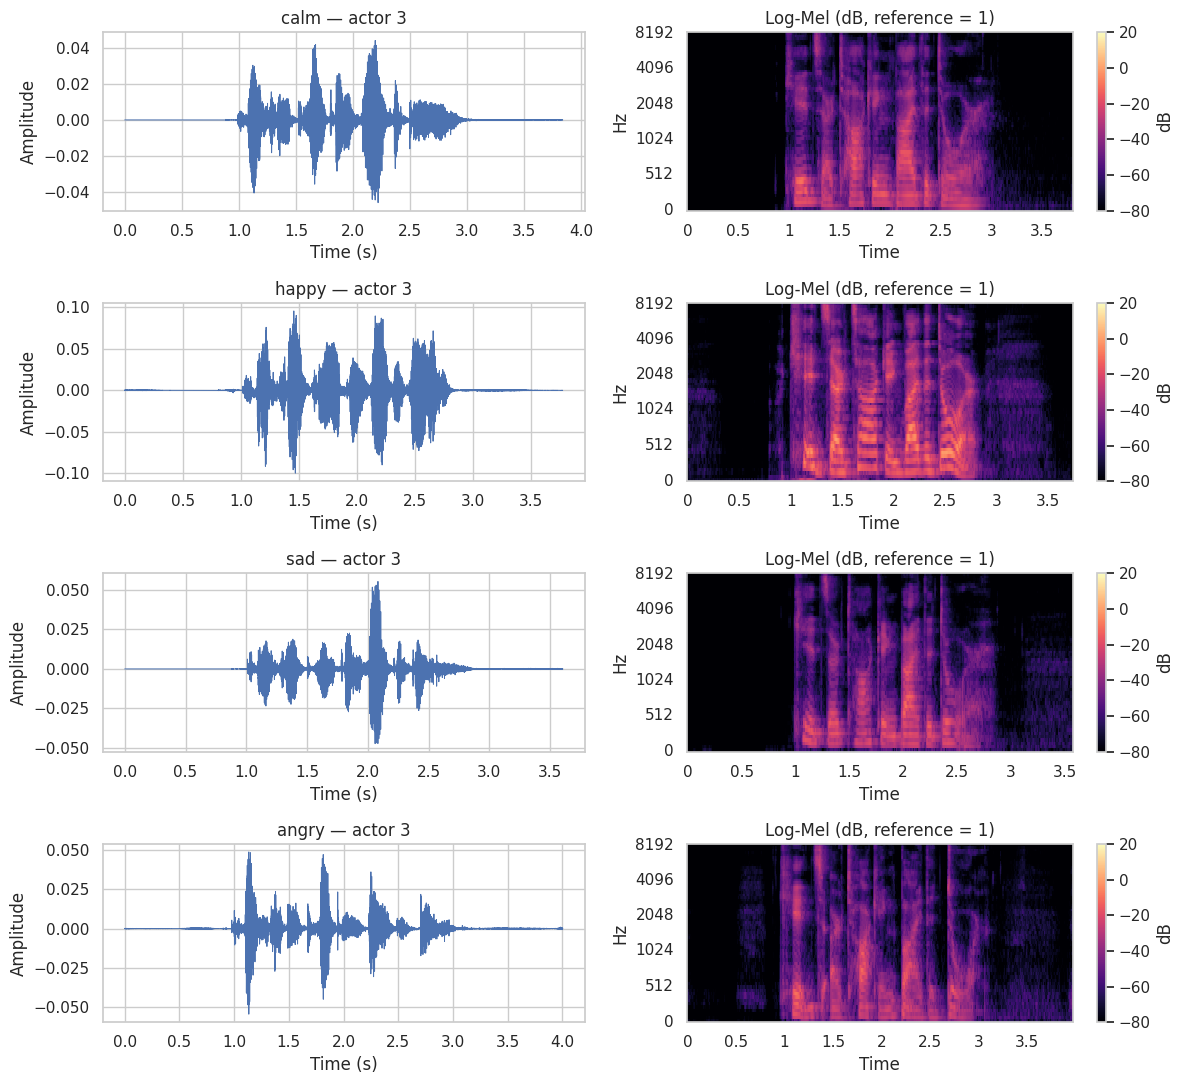

In [9]:
example_actor=int(dev.actor.min())
examples=dev[(dev.actor==example_actor)&(dev.statement==1)&(dev.intensity==1)&(dev.repetition==1)]
examples=examples.set_index('emotion').loc[LABELS].reset_index()
fig,axs=plt.subplots(4,2,figsize=(12,11))
for i,row in enumerate(examples.itertuples()):
    audio=load_audio(row.path); logmel=representations(audio)[3]
    axs[i,0].plot(np.arange(len(audio))/SR,audio,lw=.7)
    axs[i,0].set(title=f'{row.emotion} — actor {row.actor}',xlabel='Time (s)',ylabel='Amplitude')
    img=librosa.display.specshow(logmel,sr=SR,hop_length=HOP,x_axis='time',y_axis='mel',
        ax=axs[i,1],vmin=-80,vmax=20,cmap='magma')
    axs[i,1].set_title('Log-Mel (dB, reference = 1)')
    fig.colorbar(img,ax=axs[i,1],label='dB')
savefig('waveforms_logmel')
display(Audio(load_audio(examples.iloc[0].path),rate=SR))


## 8. Unsupervised Exploration: PCA and k-means

**Principal Component Analysis (PCA)** is applied to the development features after imputation and standardization. PCA combines the original features into new variables called principal components. These describe mutually orthogonal directions and are ordered from highest to lowest explained variance, allowing the data to be represented in fewer dimensions. The number of components is chosen to retain at least **95% of the variance**; the first two are used for two-dimensional visualization.

**k-means** is applied to the transformed space with **k = 4**, equal to the number of emotions considered, without supplying the labels to the algorithm. The quality of the resulting structure is described by the **silhouette score**; its correspondence with the true emotions is assessed using the **Adjusted Rand Index (ARI)**, **Normalized Mutual Information (NMI)**, and a contingency table.

In the run analyzed, retaining **95% of the variance requires 52 components**. The silhouette score is **0.107**, ARI is **0.105**, and NMI is **0.133**: the cluster structure is poorly separated and only weakly aligned with the emotion labels. Unsupervised separation does not necessarily match the separation achievable by a classifier trained with labels.

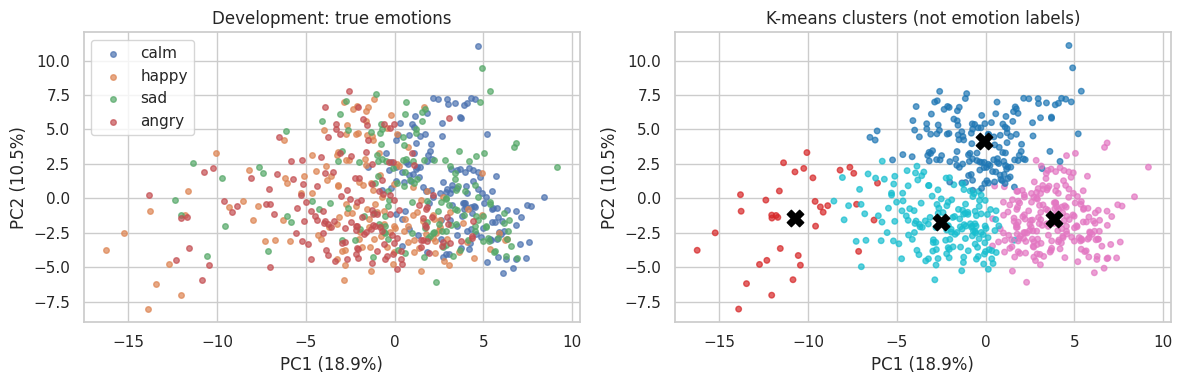

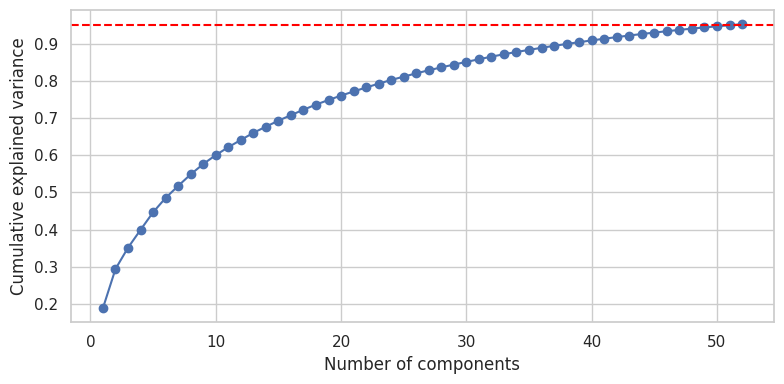

,n_components,silhouette,adjusted_rand,nmi
0,52,0.107026,0.105366,0.133076


cluster,emotion,0,1,2,3
0,angry,26,13,21,84
1,calm,53,0,89,2
2,happy,35,14,37,57
3,sad,45,9,67,23


In [10]:
explore=Pipeline([('imputer',SimpleImputer(strategy='median',keep_empty_features=True)),
    ('scale',StandardScaler()),('pca',PCA(n_components=.95,svd_solver='full'))])
Z=explore.fit_transform(Xdev)
km=KMeans(n_clusters=4,n_init=30,random_state=SEED)
clusters=km.fit_predict(Z)
pca=explore.named_steps['pca']
fig,axs=plt.subplots(1,2,figsize=(12,4))
for label in LABELS:
    mask=ydev==label; axs[0].scatter(Z[mask,0],Z[mask,1],s=16,alpha=.7,label=label)
axs[0].legend(); axs[0].set_title('Development: true emotions')
axs[1].scatter(Z[:,0],Z[:,1],c=clusters,cmap='tab10',s=16,alpha=.7)
axs[1].scatter(km.cluster_centers_[:,0],km.cluster_centers_[:,1],marker='X',s=140,c='black')
axs[1].set_title('K-means clusters (not emotion labels)')
for ax in axs:
    ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.1%})')
    ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.1%})')
savefig('pca_kmeans')
plt.figure(figsize=(8,4)); plt.plot(np.arange(1,Z.shape[1]+1),np.cumsum(pca.explained_variance_ratio_),'o-')
plt.axhline(.95,color='red',ls='--'); plt.xlabel('Number of components');plt.ylabel('Cumulative explained variance')
savefig('pca_variance')
table(pd.DataFrame([dict(n_components=Z.shape[1],silhouette=silhouette_score(Z,clusters),
    adjusted_rand=adjusted_rand_score(ydev,clusters),nmi=normalized_mutual_info_score(ydev,clusters))]),'clustering_metrics')
table(pd.crosstab(pd.Series(ydev,name='emotion'),pd.Series(clusters,name='cluster')).reset_index(),'cluster_emotion_table')


**Exploration results.** In the projection onto the first two principal components, the four emotions overlap extensively. The metrics calculated in the PCA space used by k-means also indicate poorly separated groups. Variability associated with timbre, intensity, and individual speaker characteristics may contribute to the observed dispersion. Low agreement between clusters and emotions does not imply that the classes cannot be distinguished in a supervised problem.

## 9. Feature Selection and Classifier Comparison

Two algorithms with different learning assumptions are compared. The **Support Vector Machine (SVM)** seeks a decision boundary in feature space, considering linear and **RBF** kernels. The **Random Forest (RF)** combines the predictions of multiple decision trees, introducing variability in tree construction and feature selection.

For each algorithm, two input sets are compared: **26 static MFCC descriptors** (mean and standard deviation of 13 coefficients) and the **complete 101-feature vector**. Hyperparameter search using **GridSearchCV** employs actor-based GroupKFold and optimizes **macro-F1**, which assigns equal weight to the four classes. The SVM configurations also evaluate 95%-variance PCA reduction; imputation and standardization remain inside the pipeline. The selected models are then fitted to the entire development set.

**Cross-validation results.** With 101 features, mean macro-F1 reaches **0.610 for SVM** and **0.605 for RF**, compared with **0.517** and **0.504**, respectively, with MFCC features alone. Selection therefore favors the complete set for both models. The best configurations are an **RBF SVM with C = 10 and no PCA** and an **RF with 200 trees, `max_features='sqrt'`, and `min_samples_leaf=3`**.

**Gap between training and validation.** With all 101 features, the average macro-F1 on training folds is **1.000 for SVM** and approximately **0.996 for RF**, whereas on validation folds it falls to **0.610** and **0.605**, respectively. This is a large gap, consistent with **overfitting**: the models fit the recordings used for training very well but encounter greater difficulties with previously unseen actors. Speaker variability may contribute to this difference; the scores alone, however, do not identify all its causes.

The actor-based separation makes this difficulty visible and allows configurations to be chosen based on performance on new voices rather than training scores. However, it does not eliminate overfitting. The separate test set is used to assess the selected models without using it to adjust hyperparameters.

Tuning: SVM mfcc_only
Tuning: SVM full
Tuning: RF mfcc_only
Tuning: RF full


,model,feature_set,n_features,cv_macro_f1,cv_f1_std,cv_accuracy,cv_uar,train_macro_f1,best_params
0,SVM,mfcc_only,26,0.517097,0.068486,0.526869,0.526707,0.902904,"{'clf__C': 1, 'clf__gamma': 'scale', 'clf__ker..."
1,SVM,full,101,0.609753,0.057258,0.608666,0.608488,1.000000,"{'clf__C': 10, 'clf__gamma': 'scale', 'clf__ke..."
2,RF,mfcc_only,26,0.504029,0.100818,0.511135,0.510897,1.000000,"{'clf__max_depth': None, 'clf__max_features': ..."
3,RF,full,101,0.605160,0.092420,0.610311,0.610262,0.995650,"{'clf__max_depth': None, 'clf__max_features': ..."


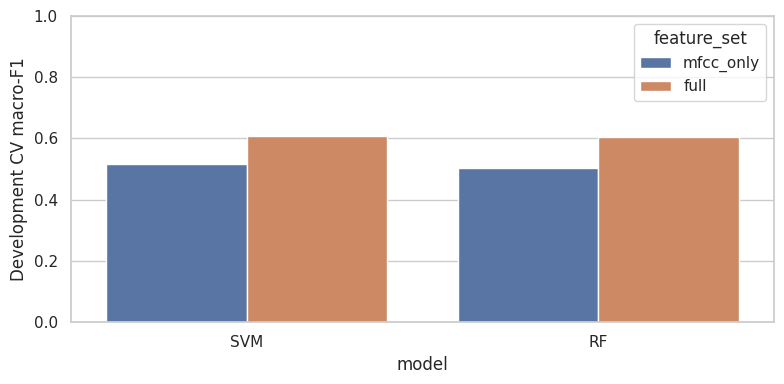

In [11]:
feature_sets={'mfcc_only':[c for c in FEATURE_NAMES if c.startswith('mfcc_')], 'full':FEATURE_NAMES}
def make_search(model):
    common=[('imputer',SimpleImputer(strategy='median',keep_empty_features=True)),
            ('scale',StandardScaler())]
    if model=='SVM':
        pipe=Pipeline(common+[('pca','passthrough'),('clf',SVC())])
        grid=[{'pca':['passthrough',PCA(n_components=.95,svd_solver='full')],
               'clf__kernel':['linear'],'clf__C':[.1,1,10]},
              {'pca':['passthrough',PCA(n_components=.95,svd_solver='full')],
               'clf__kernel':['rbf'],'clf__C':[1,10,100],'clf__gamma':['scale']}]
    else:
        pipe=Pipeline(common+[('clf',RandomForestClassifier(n_estimators=200,
            random_state=SEED,n_jobs=1))])
        grid={'clf__max_depth':[None,12],'clf__min_samples_leaf':[1,3],
              'clf__max_features':['sqrt',.5]}
    return GridSearchCV(pipe,grid,cv=cv,scoring={'f1_macro':'f1_macro','accuracy':'accuracy',
        'uar':'balanced_accuracy'},refit='f1_macro',n_jobs=N_JOBS,return_train_score=True,error_score='raise')
searches={}; cv_rows=[]
for model in ['SVM','RF']:
    for feature_set,columns in feature_sets.items():
        print('Tuning:',model,feature_set,flush=True)
        search=make_search(model).fit(Xdev[columns],ydev)
        searches[(model,feature_set)]=search
        results=pd.DataFrame(search.cv_results_)
        results.to_csv(OUT/'tables'/f'cv_grid_{model}_{feature_set}.csv',index=False)
        b=search.best_index_
        cv_rows.append(dict(model=model,feature_set=feature_set,n_features=len(columns),
            cv_macro_f1=results.loc[b,'mean_test_f1_macro'],cv_f1_std=results.loc[b,'std_test_f1_macro'],
            cv_accuracy=results.loc[b,'mean_test_accuracy'],cv_uar=results.loc[b,'mean_test_uar'],
            train_macro_f1=results.loc[b,'mean_train_f1_macro'],best_params=str(search.best_params_)))
cv_summary=pd.DataFrame(cv_rows)
table(cv_summary,'cv_model_feature_comparison')
# Select by model family before examining the test set. In case of a tie, prefer fewer features.
models={}; chosen_features={}; selections=[]
for model in ['SVM','RF']:
    best=cv_summary[cv_summary.model==model].sort_values(['cv_macro_f1','n_features'],ascending=[False,True]).iloc[0]
    models[model]=searches[(model,best.feature_set)].best_estimator_
    chosen_features[model]=feature_sets[best.feature_set]
    selections.append(dict(model=model,feature_set=best.feature_set,best_params=best.best_params,
        selection_cv_macro_f1=float(best.cv_macro_f1)))
    joblib.dump(dict(pipeline=models[model],features=chosen_features[model],config=CONFIG),OUT/'models'/f'{model}.joblib')
(OUT/'model_selection.json').write_text(json.dumps(selections,indent=2))
plt.figure(figsize=(8,4));sns.barplot(data=cv_summary,x='model',y='cv_macro_f1',hue='feature_set',errorbar=None)
plt.ylim(0,1);plt.ylabel('Development CV macro-F1');savefig('cv_feature_comparison')


## 10. Evaluation on the Clean Test Set

The selected classifiers are evaluated on the **192 recordings from actors excluded from development**, without changing their hyperparameters. Performance is compared with a **DummyClassifier** baseline, which always predicts the majority class. The metrics considered are **accuracy**, **balanced accuracy/UAR** (*Unweighted Average Recall*), and **macro-F1**, accompanied by absolute and class-normalized confusion matrices.

The **SVM** achieves **73.44% accuracy** and **0.731 macro-F1**; the **Random Forest** reaches **72.40% accuracy** and **0.708 macro-F1**. The baseline reaches only **25% accuracy** and **0.100 macro-F1**. The macro-F1 difference between SVM and RF is **0.023**, relatively small compared with the observed variability.

To account for the limited number of test actors, an **actor-block bootstrap** is used. Six actors are repeatedly sampled with replacement: the same actor may therefore appear more than once, and all of their recordings remain together during resampling. The descriptive 95% interval for the paired **SVM − RF** difference is **[−0.097; 0.129]**, and includes zero: it is therefore compatible with either an SVM advantage or an RF advantage. Thus, the clean-speech results do not demonstrate that one model is consistently superior to the other.

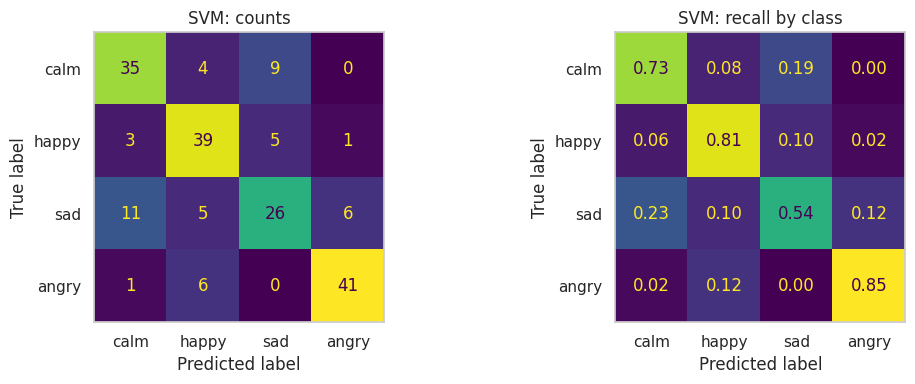

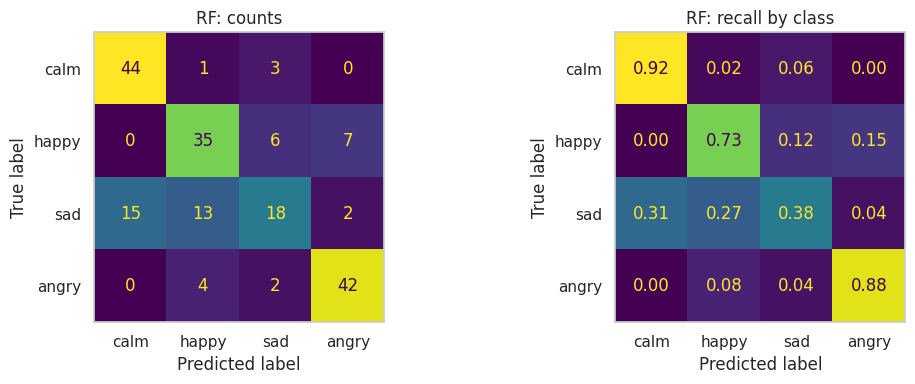

,model,accuracy,uar,macro_f1,f1_ci_low,f1_ci_high
0,SVM,0.734375,0.734375,0.731017,0.599937,0.837520
1,RF,0.723958,0.723958,0.707879,0.659145,0.756942
2,Dummy,0.250000,0.250000,0.100000,0.100000,0.100000


,model,actor,accuracy,uar,macro_f1
0,SVM,1,0.90625,0.90625,0.907639
1,SVM,2,0.84375,0.84375,0.831237
2,SVM,15,0.62500,0.62500,0.605392
3,SVM,17,0.50000,0.50000,0.475962
4,SVM,18,0.71875,0.71875,0.714286
5,SVM,24,0.81250,0.81250,0.811765
6,RF,1,0.78125,0.78125,0.775641
7,RF,2,0.81250,0.81250,0.795467
8,RF,15,0.71875,0.71875,0.722456
9,RF,17,0.68750,0.68750,0.693452


,comparison,macro_f1_difference,ci_low,ci_high
0,SVM minus RF,0.023138,-0.097215,0.129058


In [12]:
def metrics(y,p):
    return dict(accuracy=accuracy_score(y,p),uar=balanced_accuracy_score(y,p),
        macro_f1=f1_score(y,p,labels=LABELS,average='macro',zero_division=0))
def actor_bootstrap(y,p,actors,B=1000,other=None):
    rng=np.random.default_rng(SEED); unique=np.unique(actors)
    groups=[np.flatnonzero(actors==a) for a in unique]
    values=[]
    for _ in range(B):
        idx=np.concatenate([groups[i] for i in rng.integers(0,len(groups),len(groups))])
        value=f1_score(y[idx],p[idx],labels=LABELS,average='macro',zero_division=0)
        if other is not None:
            value-=f1_score(y[idx],other[idx],labels=LABELS,average='macro',zero_division=0)
        values.append(value)
    return np.percentile(values,[2.5,97.5])
clean_predictions={m:est.predict(Xtest[chosen_features[m]]) for m,est in models.items()}
dummy=DummyClassifier(strategy='most_frequent').fit(Xdev,ydev)
clean_predictions['Dummy']=dummy.predict(Xtest)
clean_rows=[]; per_actor=[]
for model,pred in clean_predictions.items():
    low,high=actor_bootstrap(ytest,pred,test.actor.to_numpy())
    clean_rows.append(dict(model=model,**metrics(ytest,pred),f1_ci_low=low,f1_ci_high=high))
    pd.DataFrame(classification_report(ytest,pred,labels=LABELS,output_dict=True,zero_division=0)).T.to_csv(
        OUT/'tables'/f'classification_report_{model}.csv')
    for actor in test_actors:
        mask=test.actor.to_numpy()==actor
        per_actor.append(dict(model=model,actor=actor,**metrics(ytest[mask],pred[mask])))
    if model!='Dummy':
        fig,axs=plt.subplots(1,2,figsize=(11,4))
        ConfusionMatrixDisplay.from_predictions(ytest,pred,labels=LABELS,ax=axs[0],colorbar=False)
        ConfusionMatrixDisplay.from_predictions(ytest,pred,labels=LABELS,normalize='true',ax=axs[1],colorbar=False,values_format='.2f')
        axs[0].set_title(f'{model}: counts');axs[1].set_title(f'{model}: recall by class')
        for ax in axs: ax.grid(False)
        savefig(f'confusion_clean_{model}')
clean_metrics=pd.DataFrame(clean_rows)
table(clean_metrics,'test_clean_metrics');table(pd.DataFrame(per_actor),'test_per_actor')
pred_table=test[['filename','actor','emotion']].copy()
for model,pred in clean_predictions.items():pred_table[model]=pred
pred_table.to_csv(OUT/'tables'/'predictions_clean.csv',index=False)
ci=actor_bootstrap(ytest,clean_predictions['SVM'],test.actor.to_numpy(),other=clean_predictions['RF'])
table(pd.DataFrame([dict(comparison='SVM minus RF',macro_f1_difference=
    metrics(ytest,clean_predictions['SVM'])['macro_f1']-metrics(ytest,clean_predictions['RF'])['macro_f1'],
    ci_low=ci[0],ci_high=ci[1])]),'paired_model_difference')


**Error analysis.** The confusion matrices reveal different sensitivities across emotions: recall for the **angry** class is relatively high (approximately **85% for SVM** and **88% for RF**), whereas **sad** is more difficult to identify (approximately **54% for SVM** and **38% for RF**). Performance also varies among individual test actors, confirming the importance of distinguishing generalization to new people from simple accuracy on files in a corpus.

## 11. Noise Generation and SNR Control

Model robustness is examined by adding three types of disturbance to clean recordings: **white Gaussian noise**, **traffic**, and **cafeteria** noise. The two environmental noises are extracted from the corresponding DEMAND recordings; white noise is synthesized numerically. The models remain those trained exclusively on clean speech.

The mixture is defined as \(x=s+\alpha n\), where \(s\) represents speech, \(n\) is zero-mean noise, and the coefficient \(\alpha\) imposes a predetermined signal-to-noise ratio:

\[
\alpha=\sqrt{\frac{P_s}{P_n\,10^{\mathrm{SNR}/10}}}.
\]

The powers \(P_s\) and \(P_n\) are calculated over the entire signal duration. At **20 dB**, the noise has a lower mean power than speech; at **0 dB**, the two mean powers are equal. For each recording and repetition, the same noise segment is used at different SNRs, changing only its scale factor.

Numerical checks are included for the actual SNR level, noise reproducibility, and pitch estimation using a known synthetic signal. The SNR value describes the entire recording, including any silences, and does not necessarily coincide with the ratio measured only over active-speech segments.

In [13]:
noise_audio={name:load_audio(p) for name,p in noise_paths.items()}
def seed_for(filename,noise_name,repeat):
    text=f'{SEED}|{filename}|{noise_name}|{repeat}'
    return int(hashlib.sha256(text.encode()).hexdigest()[:16],16)
def noise_segment(clean,filename,noise_name,repeat):
    seed=seed_for(filename,noise_name,repeat); rng=np.random.default_rng(seed)
    if noise_name=='white':
        n=rng.normal(size=len(clean)); start=-1
    else:
        recording=noise_audio[noise_name]
        assert len(recording)>=len(clean), 'DEMAND recording too short'
        start=int(rng.integers(0,len(recording)-len(clean)+1))
        n=recording[start:start+len(clean)].copy()
    return n-n.mean(),start,seed

def mix_at_snr(clean,noise,snr):
    ps=np.mean(clean**2); pn=np.mean(noise**2)
    assert ps>1e-14 and pn>1e-14
    scaled=noise*np.sqrt(ps/(pn*10**(snr/10)))
    mixed=clean+scaled
    measured=10*np.log10(ps/np.mean((mixed-clean)**2))
    assert abs(measured-snr)<1e-7
    return mixed,measured
# Checks: reproducible noise, exact SNR, and pitch of a known sine wave.
a=load_audio(test.iloc[0].path)
n,start,seed=noise_segment(a,test.iloc[0].filename,'white',0)
n2,_,_=noise_segment(a,test.iloc[0].filename,'white',0)
assert np.array_equal(n,n2)
for snr in SNR_LEVELS: mix_at_snr(a,n,snr)
tone=.2*np.sin(2*np.pi*200*np.arange(SR)/SR)
assert abs(extract_features(tone)['pitch_median']-200)<12
assert np.isnan(extract_features(np.zeros(SR))['pitch_mean'])
print('SNR, reproducibility and pitch checks: OK')


SNR, reproducibility and pitch checks: OK


## 12. Noise Robustness Evaluation

The protocol includes **192 test recordings × 3 noise types × 3 SNRs × 3 repetitions**, for a total of **5,184 mixtures**. Each mixture is evaluated by both SVM and Random Forest, yielding **10,368 predictions**. The three repeated realizations make it possible to observe variability associated with the selected noise segment or with synthetic noise generation.

For each model, noise, and SNR combination, **accuracy**, **UAR**, and **macro-F1** are calculated. The plot reports mean macro-F1 with the **standard deviation across the three repetitions**, together with the clean-test score as a reference. Confusion matrices at **0 dB** show the pattern of predictions under the most intense noise conditions.

**Results.** Random Forest maintains a higher macro-F1 than SVM in all nine noise–SNR combinations. With cafeteria noise at **20 dB**, the scores are **0.638 (RF)** and **0.318 (SVM)**; with traffic noise at **10 dB**, they are **0.385 (RF)** and **0.184 (SVM)**. With white noise at **10 and 0 dB**, the SVM reaches **macro-F1 = 0.100**, corresponding to extremely limited performance under these conditions. Both models show increasing degradation as noise intensity rises, but to different degrees.

white, repeat 1:   0%|          | 0/192 [00:00<?, ?it/s]

white, repeat 2:   0%|          | 0/192 [00:00<?, ?it/s]

white, repeat 3:   0%|          | 0/192 [00:00<?, ?it/s]

traffic, repeat 1:   0%|          | 0/192 [00:00<?, ?it/s]

traffic, repeat 2:   0%|          | 0/192 [00:00<?, ?it/s]

traffic, repeat 3:   0%|          | 0/192 [00:00<?, ?it/s]

cafeteria, repeat 1:   0%|          | 0/192 [00:00<?, ?it/s]

cafeteria, repeat 2:   0%|          | 0/192 [00:00<?, ?it/s]

cafeteria, repeat 3:   0%|          | 0/192 [00:00<?, ?it/s]

,model,noise,snr,f1_mean,f1_sd,accuracy_mean,uar_mean,f1_drop_mean
0,RF,cafeteria,0,0.313478,0.015206,0.385417,0.385417,0.394401
1,RF,cafeteria,10,0.476930,0.010102,0.520833,0.520833,0.230950
2,RF,cafeteria,20,0.638153,0.006645,0.631944,0.631944,0.069726
3,RF,traffic,0,0.188587,0.040476,0.300347,0.300347,0.519292
4,RF,traffic,10,0.385120,0.018877,0.458333,0.458333,0.322759
5,RF,traffic,20,0.595861,0.028550,0.612847,0.612847,0.112018
6,RF,white,0,0.277271,0.017606,0.364583,0.364583,0.430609
7,RF,white,10,0.398059,0.011108,0.397569,0.397569,0.309820
8,RF,white,20,0.516817,0.034249,0.529514,0.529514,0.191062
9,SVM,cafeteria,0,0.137002,0.011179,0.253472,0.253472,0.594015


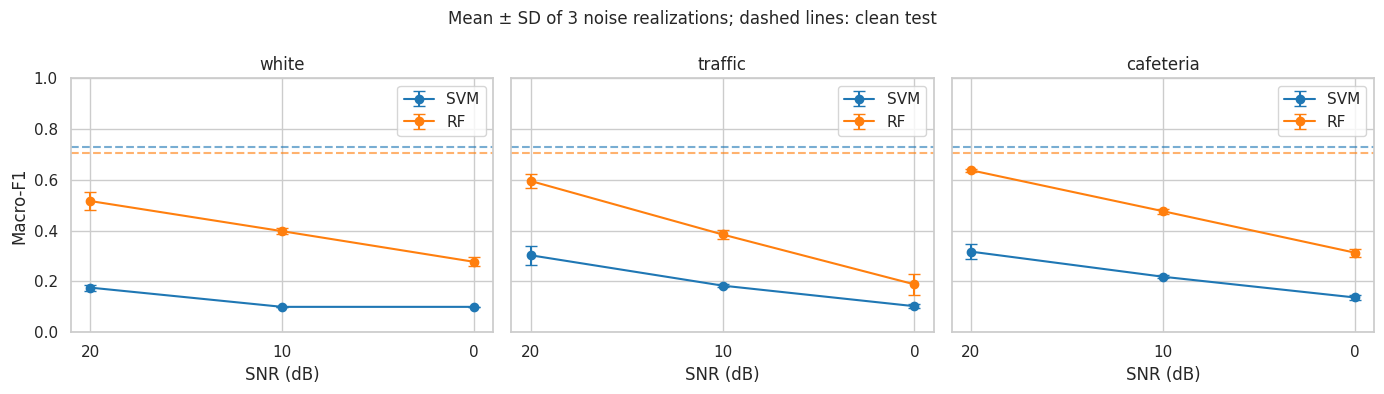

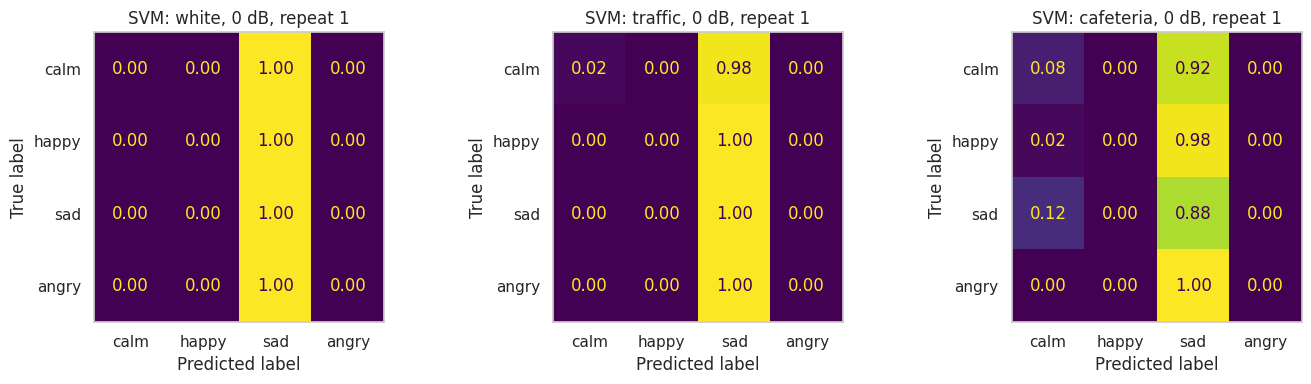

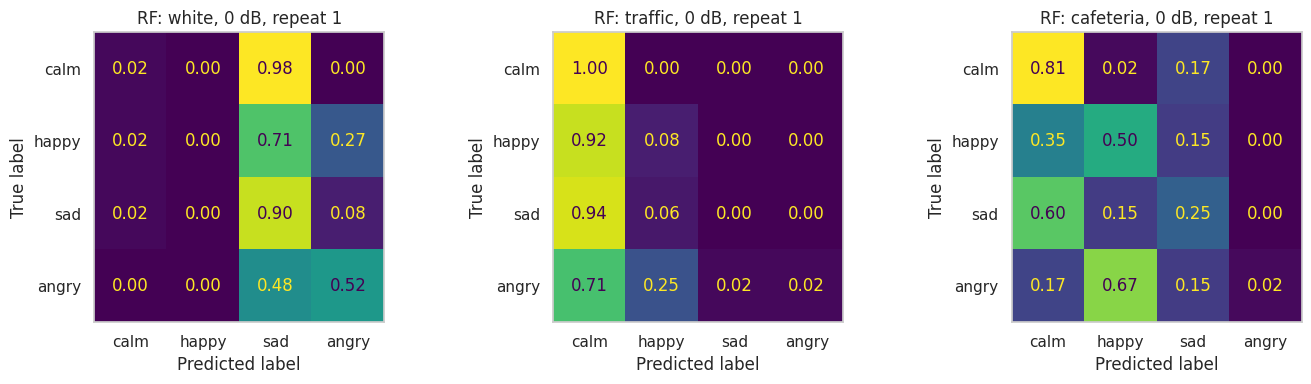

In [14]:
# Extract 192 clips × 3 noises × 3 SNRs × 3 realizations = 5,184 rows.
noise_metrics=[]; noisy_predictions=[]; mix_manifest=[]
for noise_name in ['white','traffic','cafeteria']:
    for repeat in range(NOISE_REPEATS):
        cache_file=CACHE/f'noise_{noise_name}_r{repeat}.csv'
        manifest_file=CACHE/f'mix_{noise_name}_r{repeat}.csv'
        if cache_file.exists() and manifest_file.exists():
            features=pd.read_csv(cache_file); manifests=pd.read_csv(manifest_file)
        else:
            rows=[]; manifest_rows=[]
            for row in tqdm(test.itertuples(),total=len(test),desc=f'{noise_name}, repeat {repeat+1}'):
                clean=load_audio(row.path)
                noise,start,seed=noise_segment(clean,row.filename,noise_name,repeat)
                for snr in SNR_LEVELS:
                    mixed,measured=mix_at_snr(clean,noise,snr)
                    rows.append(dict(filename=row.filename,snr=snr,**extract_features(mixed)))
                    manifest_rows.append(dict(filename=row.filename,noise=noise_name,repeat=repeat,snr=snr,
                        measured_snr=measured,start_sample=start,n_samples=len(clean),seed=str(seed),
                        peak_absolute=float(np.max(np.abs(mixed)))))
            features=pd.DataFrame(rows);manifests=pd.DataFrame(manifest_rows)
            features.to_csv(cache_file,index=False);manifests.to_csv(manifest_file,index=False)
        assert len(features)==len(test)*len(SNR_LEVELS)
        mix_manifest.append(manifests)
        for snr in SNR_LEVELS:
            subset=features[features.snr==snr].set_index('filename').loc[test.filename,FEATURE_NAMES].reset_index(drop=True)
            for model,est in models.items():
                pred=est.predict(subset[chosen_features[model]])
                clean_f1=metrics(ytest,clean_predictions[model])['macro_f1']
                score=metrics(ytest,pred)
                noise_metrics.append(dict(model=model,noise=noise_name,repeat=repeat,snr=snr,
                    **score,f1_drop=clean_f1-score['macro_f1']))
                for i,row in enumerate(test.itertuples()):
                    noisy_predictions.append(dict(filename=row.filename,actor=row.actor,emotion=row.emotion,
                        model=model,noise=noise_name,repeat=repeat,snr=snr,prediction=pred[i]))
noise_metrics=pd.DataFrame(noise_metrics);noisy_predictions=pd.DataFrame(noisy_predictions)
noise_metrics.to_csv(OUT/'tables'/'noise_metrics_each_repeat.csv',index=False)
noisy_predictions.to_csv(OUT/'tables'/'predictions_noisy.csv',index=False)
pd.concat(mix_manifest,ignore_index=True).to_csv(OUT/'tables'/'noise_mix_manifest.csv',index=False)
summary=noise_metrics.groupby(['model','noise','snr']).agg(
    f1_mean=('macro_f1','mean'),f1_sd=('macro_f1','std'),accuracy_mean=('accuracy','mean'),
    uar_mean=('uar','mean'),f1_drop_mean=('f1_drop','mean')).reset_index()
table(summary,'noise_summary')
fig,axs=plt.subplots(1,3,figsize=(14,4),sharey=True)
for ax,noise_name in zip(axs,['white','traffic','cafeteria']):
    for model,color in [('SVM','tab:blue'),('RF','tab:orange')]:
        part=summary[(summary.model==model)&(summary.noise==noise_name)].set_index('snr').loc[SNR_LEVELS]
        ax.errorbar(SNR_LEVELS,part.f1_mean,yerr=part.f1_sd,marker='o',label=model,color=color,capsize=4)
        ax.axhline(metrics(ytest,clean_predictions[model])['macro_f1'],color=color,ls='--',alpha=.6)
    ax.set(title=noise_name,xlabel='SNR (dB)',xticks=SNR_LEVELS,ylim=(0,1));ax.invert_xaxis();ax.legend()
axs[0].set_ylabel('Macro-F1')
fig.suptitle('Mean ± SD of 3 noise realizations; dashed lines: clean test', fontsize=12)
savefig('noise_robustness')
# Matrices at 0 dB: one predetermined realization, not a post-hoc selection.
for model in models:
    fig,axs=plt.subplots(1,3,figsize=(14,4))
    for ax,noise_name in zip(axs,['white','traffic','cafeteria']):
        part=noisy_predictions[(noisy_predictions.model==model)&(noisy_predictions.noise==noise_name)&
            (noisy_predictions.snr==0)&(noisy_predictions.repeat==0)]
        ConfusionMatrixDisplay.from_predictions(part.emotion,part.prediction,labels=LABELS,
            normalize='true',ax=ax,colorbar=False,values_format='.2f')
        ax.set_title(f'{model}: {noise_name}, 0 dB, repeat 1')
        ax.grid(False)
    savefig(f'confusion_noise_0dB_{model}')


**Comparison with the clean test set.** RF macro-F1 drops from **0.708** on clean speech to **0.638** with cafeteria noise at 20 dB and **0.313** at 0 dB. SVM starts at **0.731** and falls to **0.318** and **0.137**, respectively. Under the protocol considered, RF therefore retains more of its predictive ability in the presence of disturbances not observed during training.

**Concentration of SVM predictions.** In the confusion matrix with white noise at **0 dB**, referring to the first predetermined realization, SVM assigns all **192 recordings to the `sad` class**, regardless of the true emotion. Thus, the model is not simply choosing classes at random: under this condition, its predictions concentrate on a single label. Since the test set contains 48 recordings per emotion, this choice produces **accuracy = 0.25** and **macro-F1 = 0.100**. Precision for the `sad` class is 0.25 and its recall is 1, yielding F1 = 0.40; the other three classes have zero F1, and the average is 0.100.

The table reports macro-F1 equal to 0.100 in all repetitions with white noise at 10 and 0 dB; the identity of the predicted class must be checked in the predictions rather than inferred from the score alone. The matrices shown for traffic and cafeteria noise at 0 dB also reveal a strong concentration toward `sad`. This behavior is consistent with a **shift between the features of clean and noisy audio**, but does not by itself establish which descriptors cause it. Permutation importance on the clean test set describes which features the models depend on under that condition, without directly explaining their collapse under noise.

## 13. Variability in Performance Loss

The macro-F1 loss relative to the clean test is defined as \(\Delta F1 = F1_{\mathrm{clean}}-F1_{\mathrm{noise}}\). A positive value indicates a decrease in performance after adding noise. The variability of this difference is described using an **actor-block bootstrap** and **95%** percentile intervals.

At each resampling, actors are drawn with replacement, and all recordings belonging to each selected actor are included together. In this way, audio clips from the same person are not treated as independent observations. The three noise realizations are averaged within each resample rather than treated as independent subjects. The analysis uses **500 resamples**.

The resulting intervals describe uncertainty conditional on the **six test actors** and the specific noise recordings. They do not represent a universal interval for generalization to new corpora, new environments, or any speaker population.

In [15]:
groups=[np.flatnonzero(test.actor.to_numpy()==a) for a in test_actors]
rng=np.random.default_rng(SEED)
bootstrap_indices=[np.concatenate([groups[i] for i in rng.integers(0,len(groups),len(groups))]) for _ in range(500)]
drop_rows=[]
for model in models:
    for noise_name in ['white','traffic','cafeteria']:
        for snr in SNR_LEVELS:
            predictions=[]
            for repeat in range(NOISE_REPEATS):
                part=noisy_predictions[(noisy_predictions.model==model)&(noisy_predictions.noise==noise_name)&
                    (noisy_predictions.snr==snr)&(noisy_predictions.repeat==repeat)]
                predictions.append(part.set_index('filename').loc[test.filename,'prediction'].to_numpy())
            drops=[]
            for idx in bootstrap_indices:
                clean_score=f1_score(ytest[idx],clean_predictions[model][idx],labels=LABELS,average='macro',zero_division=0)
                noisy_score=np.mean([f1_score(ytest[idx],p[idx],labels=LABELS,average='macro',zero_division=0) for p in predictions])
                drops.append(clean_score-noisy_score)
            low,high=np.percentile(drops,[2.5,97.5])
            drop_rows.append(dict(model=model,noise=noise_name,snr=snr,drop_ci_low=low,drop_ci_high=high))
table(summary.merge(pd.DataFrame(drop_rows),on=['model','noise','snr']),'noise_drop_intervals')


,model,noise,snr,f1_mean,f1_sd,accuracy_mean,uar_mean,f1_drop_mean,drop_ci_low,drop_ci_high
0,RF,cafeteria,0,0.313478,0.015206,0.385417,0.385417,0.394401,0.346632,0.452403
1,RF,cafeteria,10,0.476930,0.010102,0.520833,0.520833,0.230950,0.202220,0.265227
2,RF,cafeteria,20,0.638153,0.006645,0.631944,0.631944,0.069726,0.045289,0.099676
3,RF,traffic,0,0.188587,0.040476,0.300347,0.300347,0.519292,0.435816,0.582560
4,RF,traffic,10,0.385120,0.018877,0.458333,0.458333,0.322759,0.292005,0.360710
5,RF,traffic,20,0.595861,0.028550,0.612847,0.612847,0.112018,0.049914,0.169926
6,RF,white,0,0.277271,0.017606,0.364583,0.364583,0.430609,0.353623,0.499254
7,RF,white,10,0.398059,0.011108,0.397569,0.397569,0.309820,0.241377,0.398106
8,RF,white,20,0.516817,0.034249,0.529514,0.529514,0.191062,0.148900,0.235369
9,SVM,cafeteria,0,0.137002,0.011179,0.253472,0.253472,0.594015,0.490119,0.688803


## 14. Explainable AI: Feature Importance

**Permutation feature importance** assesses the predictive contribution of a feature by measuring how much **macro-F1** decreases when its values are shuffled across recordings, keeping the trained classifier unchanged. The analysis is applied to both models on the clean test set, for both individual descriptors and acoustic feature families: **MFCC, delta, delta-delta, energy/ZCR, pitch/periodicity, and spectral descriptors**.

For feature families, all columns belonging to the same group are permuted using a common order, preserving their internal relationships. Family-level comparison is useful when several features are correlated and permuting a single column in isolation may underestimate their overall role.

**MFCCs** produce the largest decrease in macro-F1 when permuted as a group: approximately **0.290 for SVM** and **0.133 for RF**. They are followed, respectively, by **delta** for SVM (**0.125**) and **energy/ZCR** for RF (**0.071**). These values indicate how much the models depend on the different feature families in the test set considered. They do not demonstrate that a feature causes an emotion. Furthermore, groups contain different numbers of variables: greater group importance does not imply greater importance for each of its individual features.

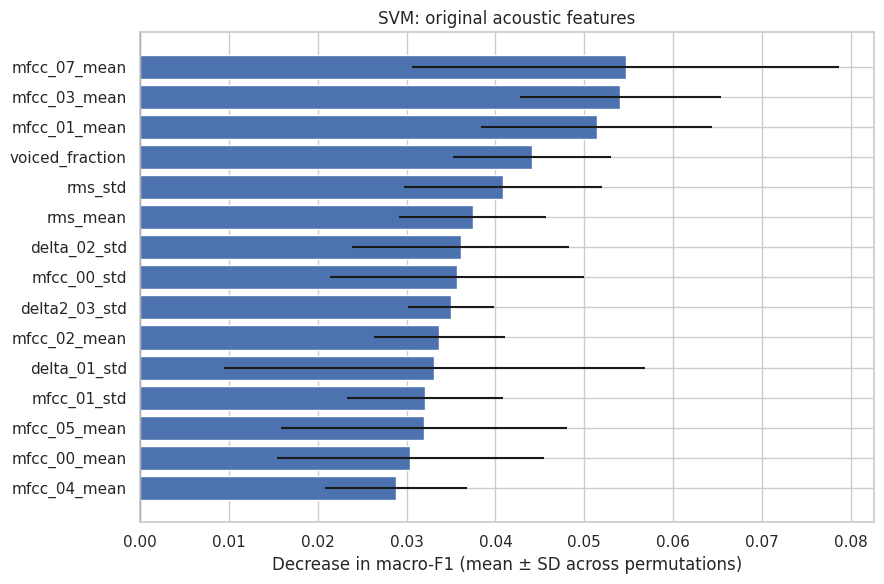

,family,n_features,importance_mean,importance_std
5,Spectral descriptors,12,0.046375,0.019890
4,Pitch / periodicity,7,0.059275,0.031059
2,Energy / ZCR,4,0.068158,0.021461
1,Delta2,26,0.071005,0.024937
0,Delta,26,0.125378,0.021796
3,MFCC,26,0.289689,0.025976


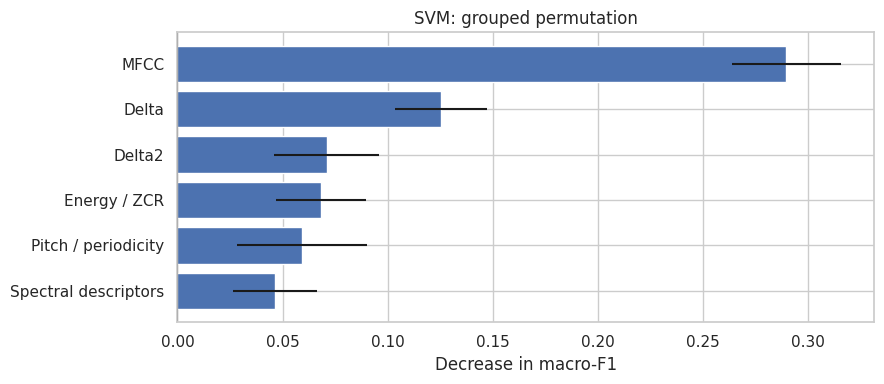

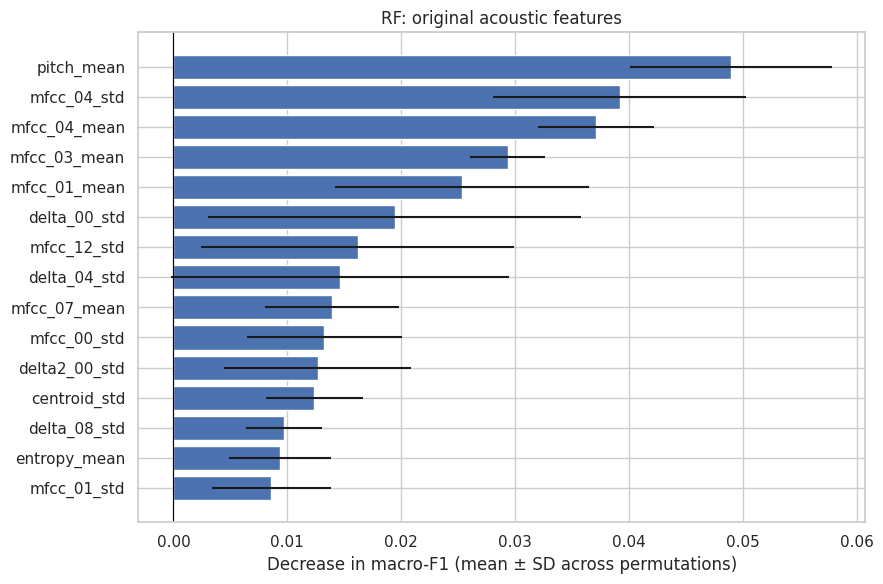

,family,n_features,importance_mean,importance_std
5,Spectral descriptors,12,0.019944,0.016957
4,Pitch / periodicity,7,0.027117,0.016339
1,Delta2,26,0.042617,0.018756
0,Delta,26,0.057724,0.021674
2,Energy / ZCR,4,0.070884,0.027309
3,MFCC,26,0.132748,0.026478


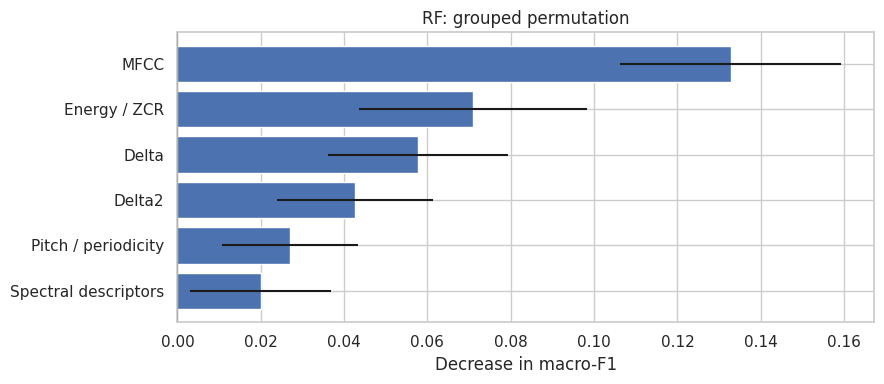

In [16]:
def feature_family(c):
    if c.startswith('mfcc_'):return 'MFCC'
    if c.startswith('delta2_'):return 'Delta2'
    if c.startswith('delta_'):return 'Delta'
    if c.startswith(('pitch_','voiced_','periodicity_')):return 'Pitch / periodicity'
    if c.startswith(('rms_','zcr_')):return 'Energy / ZCR'
    return 'Spectral descriptors'
for model,est in models.items():
    cols=chosen_features[model]; X=Xtest[cols]
    result=permutation_importance(est,X,ytest,scoring='f1_macro',n_repeats=5,random_state=SEED,n_jobs=N_JOBS)
    imp=pd.DataFrame(dict(feature=cols,importance_mean=result.importances_mean,importance_std=result.importances_std))
    imp=imp.sort_values('importance_mean',ascending=False)
    imp.to_csv(OUT/'tables'/f'permutation_{model}.csv',index=False)
    top=imp.head(15).iloc[::-1]
    plt.figure(figsize=(9,6));plt.barh(top.feature,top.importance_mean,xerr=top.importance_std)
    plt.axvline(0,color='black',lw=.8);plt.xlabel('Decrease in macro-F1 (mean ± SD across permutations)')
    plt.title(f'{model}: original acoustic features');savefig(f'permutation_{model}')
    grouped=[]; base=metrics(ytest,est.predict(X))['macro_f1']
    for family in sorted({feature_family(c) for c in cols}):
        selected=[c for c in cols if feature_family(c)==family]
        rng=np.random.default_rng(SEED); drops=[]
        for repeat in range(20):
            shuffled=X.copy();order=rng.permutation(len(X))
            shuffled.loc[:,selected]=X.iloc[order][selected].to_numpy()
            drops.append(base-metrics(ytest,est.predict(shuffled))['macro_f1'])
        grouped.append(dict(family=family,n_features=len(selected),importance_mean=np.mean(drops),importance_std=np.std(drops)))
    grouped=pd.DataFrame(grouped).sort_values('importance_mean')
    table(grouped,f'grouped_permutation_{model}')
    plt.figure(figsize=(9,4));plt.barh(grouped.family,grouped.importance_mean,xerr=grouped.importance_std)
    plt.axvline(0,color='black',lw=.8);plt.xlabel('Decrease in macro-F1');plt.title(f'{model}: grouped permutation')
    savefig(f'grouped_permutation_{model}')


## 15. Archiving the Experiments

The configuration, split protocols, metric tables, predictions, figures, and trained classifiers are collected in the **`APR_results.zip`** archive. Storing results and settings together makes it possible to verify how the reported values and plots were obtained. The original audio signals are not included in the results archive.

In [17]:
# Export results, models, and configuration. Cache and audio are excluded.
result_zip=OUT/'APR_results.zip'
with zipfile.ZipFile(result_zip,'w',compression=zipfile.ZIP_DEFLATED) as z:
    for folder in ['figures','tables','models']:
        for p in sorted((OUT/folder).rglob('*')):
            if p.is_file():z.write(p,p.relative_to(OUT))
    for p in OUT.glob('*.json'): z.write(p,p.name)
print('Completed. Results:',result_zip)
if IN_COLAB:
    from google.colab import files
    files.download(str(result_zip))


Completed. Results: /content/APR_output/APR_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 16. Discussion and Conclusions

The results indicate that aggregated acoustic features contain useful information for distinguishing the four acted emotions in RAVDESS, even when the test actors are absent from the development set. On **clean speech**, both algorithms clearly outperform the baseline; SVM achieves a slightly higher macro-F1 (**0.731 versus 0.708**), but the paired actor-based comparison does not support a strong conclusion about model superiority.

The **PCA/k-means** exploration shows that the emotions do not spontaneously form well-separated clusters in feature space. This finding is compatible with more effective supervised classification, because label-based optimization can exploit relationships not captured by unsupervised grouping. The selection of the full **101-feature vector**, outperforming the 26 MFCC-only features in cross-validation, suggests the usefulness of combining cepstral, temporal, spectral, and periodicity information.

The most striking result concerns the **change in performance under noisy conditions**. SVM, which is competitive on clean audio, rapidly loses effectiveness in all three noise scenarios. Random Forest shows generally less severe degradation and maintains an advantage across all noise–SNR combinations studied. Permutation importance highlights the substantial contribution of MFCCs, without establishing a causal relationship between individual features and emotions.

The large gap between training and validation (**1.000 versus 0.610 for SVM; 0.996 versus 0.605 for RF**) also highlights the difficulty of generalizing to new speakers. In the first realization of white noise at 0 dB, SVM predicts only `sad`: this case shows why it is useful to examine confusion matrices as well as aggregate scores.

### Study Limitations

- **Nature of the recordings:** RAVDESS contains acted emotional expressions and controlled statements; the results do not demonstrate immediate transferability to spontaneous conversations.
- **Number of speakers:** the test includes six actors; between-person variability limits the precision of generalization estimates.
- **Training on clean audio:** noise creates a mismatch between training and test conditions. Neither training with noisy data augmentation nor noise removal methods were investigated.
- **Aggregated representation:** means and standard deviations reduce temporal sequences to fixed vectors, losing some of the dynamics of speech.
- **Acoustic protocol:** SNRs are calculated over the whole clip, with three realizations per condition and specific environmental noise sources; they do not cover the full variability of real-world contexts.
- **Interpretability:** permutation-based importance values describe how predictions depend on features in the observed sample, without demonstrating causal mechanisms.

**Conclusion.** In the experimental setting considered, speech emotion recognition is feasible using models based on acoustic features, but performance depends strongly on recording conditions. The comparison highlights the importance of evaluating not only accuracy on a clean signal but also the model's ability to maintain useful performance in the presence of noise.